# KOA LFC Wavelength Solution

<span style="color:red">The HISPEC DRP is in active development. Please submit issues and suggestions on the [GitHub](https://github.com/oirlab/HISPEC_DRP).</span>

Copy of the simulated LFC example, but the WAVE product comes from the KOA caldb `lfc_wavesol` instead of painting a new comb and running `ProcessLFCPipeline`.

Section 1 still paints an HDF-centered comb only so the full-frame / three-order zoom figure can be generated. That rate map is **not** the WAVE source. Section 2 downloads the KOA `lfc_wavesol`. Section 3 makes the same `LFC − HDF` plots versus pixel and versus wavelength.

> **Setup.** Set these in your shell / notebook kernel before running (or let the first cell create a local cache under `OUT`):
>
> | Variable | Required when | Purpose |
> |---|---|---|
> | `KOA_CALIBRATION_CACHE` | Always | Local KOA calibration cache directory (and SQLite DB) |
> | `KECK_OBSERVER_EMAIL` | Remote sync | Keck Observer account email |
> | `KECK_OBSERVER_PASSWORD` | Remote sync | Keck Observer account password |


In [1]:
import os
from pathlib import Path

import numpy as np

from hispecdrp.simulations.e2e_pipeline import resolve_lfc_fiber_object

OUT = Path("/Users/ckilpatrick/hispec_koa_lfc_wavesol_example")
OUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("KOA_CALIBRATION_CACHE", str(OUT / "cals" / "KOA_CALIBRATION_CACHE"))

SPECTROGRAPH, FIBER = "BSPEC", 2
FIBER_OBJECT = resolve_lfc_fiber_object(SPECTROGRAPH)
EDGE = 0.05
MODE_STRIDE = 10
A_PIX, B_PIX, PA_DEG = 0.80, 0.55, 20.0
PA_RAD = np.deg2rad(PA_DEG)
PEAK_VALUE = 1.0e6

print(f"OUT = {OUT}")
print("KOA_CALIBRATION_CACHE:", os.environ["KOA_CALIBRATION_CACHE"])
print(f"fiber={FIBER}  {FIBER_OBJECT}  mode_stride={MODE_STRIDE}")


OUT = /Users/ckilpatrick/hispec_koa_lfc_wavesol_example
KOA_CALIBRATION_CACHE: /Users/ckilpatrick/hispec_koa_lfc_wavesol_example/cals/KOA_CALIBRATION_CACHE
fiber=2  LFC-B  mode_stride=10


## 1. HDF LFC geometry preview

Paint elliptical Gaussians at HDF deposit centers so the full-frame rate map and three order zooms can be generated (same figure as the simulated-LFC notebook). This frame is not extracted and is not passed to `ProcessLFCPipeline`.


In [2]:
from astropy.io import fits

from hispecdrp.simulations.e2e_pipeline import (
    build_lfc_line_list,
    paint_elliptical_gaussian_comb,
)

line_list, lfc_meta = build_lfc_line_list(
    SPECTROGRAPH,
    fiber=FIBER,
    fiber_object=FIBER_OBJECT,
    edge_margin_frac=EDGE,
    mode_stride=MODE_STRIDE,
)
n_per = [len(v) for v in line_list.values()]
n_tot = int(sum(n_per))
print(f"orders={len(line_list)}  modes={n_tot}")

rate = paint_elliptical_gaussian_comb(
    line_list,
    spectrograph=SPECTROGRAPH,
    fiber=FIBER,
    a_pix=A_PIX,
    b_pix=B_PIX,
    pa_rad=PA_RAD,
    peak_value=PEAK_VALUE,
)
rate_path = OUT / "rate_map.fits"
hdr = fits.Header()
hdr["SPECTRO"] = SPECTROGRAPH
hdr["FIBER"] = FIBER
hdr["OBJFIB2"] = FIBER_OBJECT
hdr["LFCNU0"] = (lfc_meta["nu0"], "LFC pump frequency [Hz]")
hdr["LFCDELNU"] = (lfc_meta["delta_nu"], "LFC mode spacing [Hz]")
fits.PrimaryHDU(rate.astype(np.float32), header=hdr).writeto(
    rate_path, overwrite=True
)
print(f"rate_map peak={rate.max():.3e} -> {rate_path}")


orders=39  modes=828
rate_map peak=1.000e+06 -> /Users/ckilpatrick/hispec_koa_lfc_wavesol_example/rate_map.fits


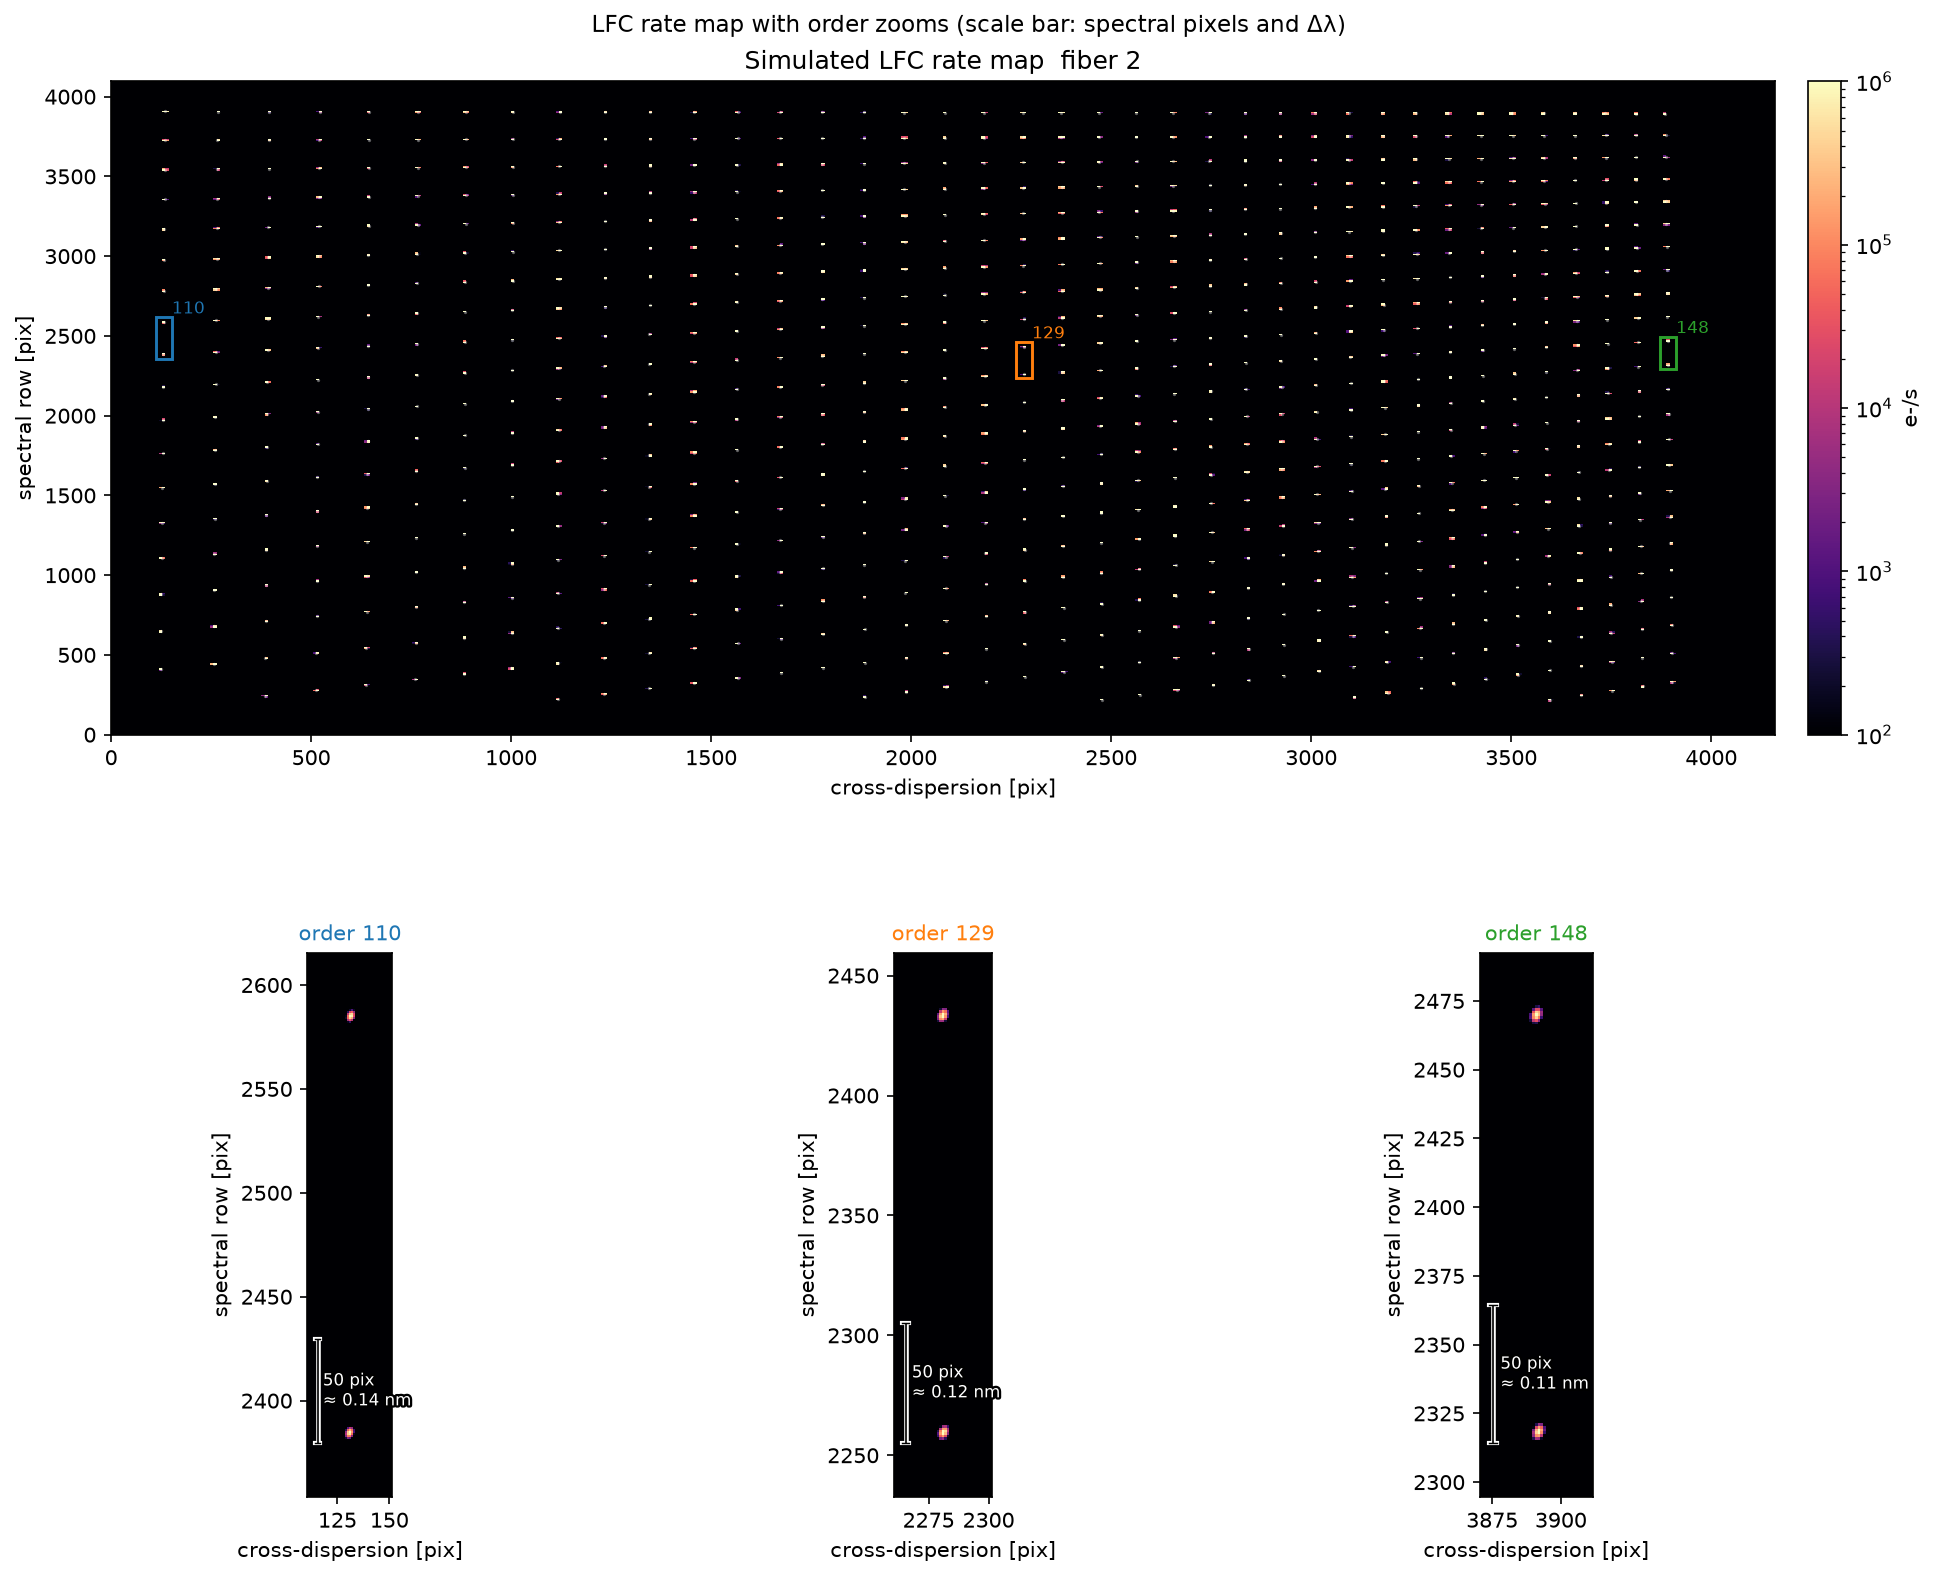

{'fiber': 2,
 'orders': [110, 129, 148],
 'zooms': [{'order': 110,
   'row_slice': (2354, 2616),
   'col_slice': (111, 152),
   'scale_bar_pix': 50.0,
   'scale_bar_dlam_um': 0.00014402890626436519},
  {'order': 129,
   'row_slice': (2233, 2460),
   'col_slice': (2261, 2302),
   'scale_bar_pix': 50.0,
   'scale_bar_dlam_um': 0.00012189374490942683},
  {'order': 148,
   'row_slice': (2295, 2493),
   'col_slice': (3871, 3912),
   'scale_bar_pix': 50.0,
   'scale_bar_dlam_um': 0.000105681150058753}],
 'out_path': '/Users/ckilpatrick/hispec_koa_lfc_wavesol_example/lfc_rate_map_order_zooms.png'}

In [3]:
from hispecdrp.simulations.plotting import plot_lfc_rate_map_order_zooms

plot_lfc_rate_map_order_zooms(
    rate,
    line_list,
    spectrograph=SPECTROGRAPH,
    fiber=FIBER,
    out_path=OUT / "lfc_rate_map_order_zooms.png",
)


## 2. Download the KOA / Keck WAVE

Prefer the remote KOA `lfc_wavesol`. If observer login fails, use the Keck-origin BSPEC master `sim_wavesol` from the HISPEC cal distribution (same `origin=KECK` product the pipeline tests download). Packaged `sim_hdf_wavesol.line_zp` files are skipped.


In [4]:
from hispecdrp import datamodels
from hispecdrp.calibrations import (
    HISPECCalibrationStore,
    seed_koa_calibration_cache,
    verify_koa_calibrations,
)
from hispecdrp.datamodels.hispec_config import HISPECConfig
from hispecdrp.utils import download_gdrive_file

KECK_MASTER_WAVESOL = {
    "BSPEC": "HISPEC/Cals/HB.20260606.00000.00.mastercal-sim_wavesol.001.fits",
    "RSPEC": "HISPEC/Cals/HR.20260606.00000.00.mastercal-sim_wavesol.001.fits",
}


def _is_packaged_line_zp(row: dict) -> bool:
    blob = f"{row.get('note') or ''} {row.get('filename') or ''}"
    return "sim_hdf_wavesol.line_zp" in blob


def _as_rows(raw) -> list[dict]:
    if raw is None:
        return []
    if isinstance(raw, dict):
        return [raw]
    return [row for row in raw if isinstance(row, dict)]


def _koa_wave_rows(rows: list[dict], cal_type: str) -> list[dict]:
    want = str(cal_type).strip().lower()
    out = []
    for row in rows:
        if str(row.get("cal_type") or "").strip().lower() != want:
            continue
        spec = str(row.get("spectrograph") or "").strip().upper()
        if spec and spec != SPECTROGRAPH:
            continue
        if _is_packaged_line_zp(row):
            continue
        out.append(row)
    out.sort(key=lambda r: float(r.get("mjd_start") or 0.0), reverse=True)
    return out


def _query_remote(store, cal_type: str) -> list[dict]:
    if getattr(store, "remote_db", None) is None:
        return []
    return _as_rows(store.remote_db.query(cal_type=cal_type))


seed = seed_koa_calibration_cache()
print(
    f"seeded={seed.get('seeded')}  source={seed.get('source')}  "
    f"fits={seed.get('n_fits_after')}"
)

summary = verify_koa_calibrations(
    SPECTROGRAPH,
    require_complete=False,
    download_missing=False,
)
print(
    f"{summary['spectrograph']} caldb: {summary['n_records']} record(s); "
    f"mode={summary.get('remote_mode')}"
)
if summary.get("remote_error"):
    print("remote:", summary["remote_error"])
print("types:", summary.get("cal_types"))

wavesol_path = None
wavesol_rec = {"filename": None, "origin": None}
source = None
with HISPECCalibrationStore(connect_remote=True, sync_on_init=False) as store:
    rows = _as_rows(store.local_db.query())
    for cal_type in ("lfc_wavesol", "sim_wavesol"):
        chosen = _koa_wave_rows(rows, cal_type)
        if not chosen:
            remote = _query_remote(store, cal_type)
            chosen = _koa_wave_rows(remote, cal_type)
            print(f"remote {cal_type} rows={len(remote)}")
        print(f"{cal_type}: {len(chosen)} usable row(s)")
        for row in chosen[:4]:
            print(
                f"  {row.get('filename')}  origin={row.get('origin')}  "
                f"mjd={row.get('mjd_start')}"
            )
        if chosen:
            wavesol_path, wavesol_rec = store.get_calibration(chosen[0])
            source = f"caldb:{cal_type}"
            break

if wavesol_path is None:
    gdrive_key = KECK_MASTER_WAVESOL[SPECTROGRAPH]
    wavesol_path = download_gdrive_file(gdrive_key, output_dir=str(OUT))
    wavesol_rec = {"filename": Path(wavesol_path).name, "origin": "KECK"}
    source = "gdrive:sim_wavesol"
    print(f"KOA login/catalog empty; using Keck-origin master WAVE {gdrive_key}")

wavesol_model = datamodels.open(str(wavesol_path))
order_list = HISPECConfig.get_order_list(SPECTROGRAPH)
if hasattr(wavesol_model, "make_order_vec"):
    order_list = [int(o) for o in np.asarray(wavesol_model.make_order_vec())]
lfc_wave = np.asarray(getattr(wavesol_model, f"wave_fib{FIBER}"), dtype=float)
print(
    f"using {wavesol_rec.get('filename')}  origin={wavesol_rec.get('origin')}  "
    f"source={source}  WAVE {lfc_wave.shape}  n_orders={len(order_list)}"
)
print(f"local file: {wavesol_path}")


[2026-10-09T11:52:20][hispecdrp.calibrations.koa_sync:412][WARNING]: No KOA cache seed found for dest=/Users/ckilpatrick/hispec_koa_lfc_wavesol_example/cals/KOA_CALIBRATION_CACHE (set HISPEC_KOA_CACHE_SEED or pass sources=...).
seeded=False  source=None  fits=0
[2026-10-09T11:52:20][koa_middleware.store:186][INFO]: Cache initialized: cache_dir='/Users/ckilpatrick/hispec_koa_lfc_wavesol_example/cals/KOA_CALIBRATION_CACHE', data_dir='/Users/ckilpatrick/hispec_koa_lfc_wavesol_example/cals/KOA_CALIBRATION_CACHE/calibrations/hispec/', db='/Users/ckilpatrick/hispec_koa_lfc_wavesol_example/cals/KOA_CALIBRATION_CACHE/database/hispec_calibrations.db', table='hispec'
[2026-10-09T11:52:20][koa_middleware.keck_client:51][INFO]: No valid login detected, logging in...
[2026-10-09T11:52:22][koa_middleware.keck_client:128][ERROR]: Login failed: Failed login attempt. Incorrect password or email address.
[2026-10-09T11:52:22][hispecdrp.calibrations.hispec_store:80][WARNING]: Remote KOA unavailable (Valu

## 3. KOA WAVE vs `get_wavelength_solution`

Same comparison as the simulated-LFC notebook: KOA `wave_fib*` minus `SimulateRateMap.get_wavelength_solution`, versus pixel (full detector and 800–3500) and versus `λ_LFC` in 1.13–1.17 µm.


flipped KOA WAVE along the spectral axis to match HDF pixel convention


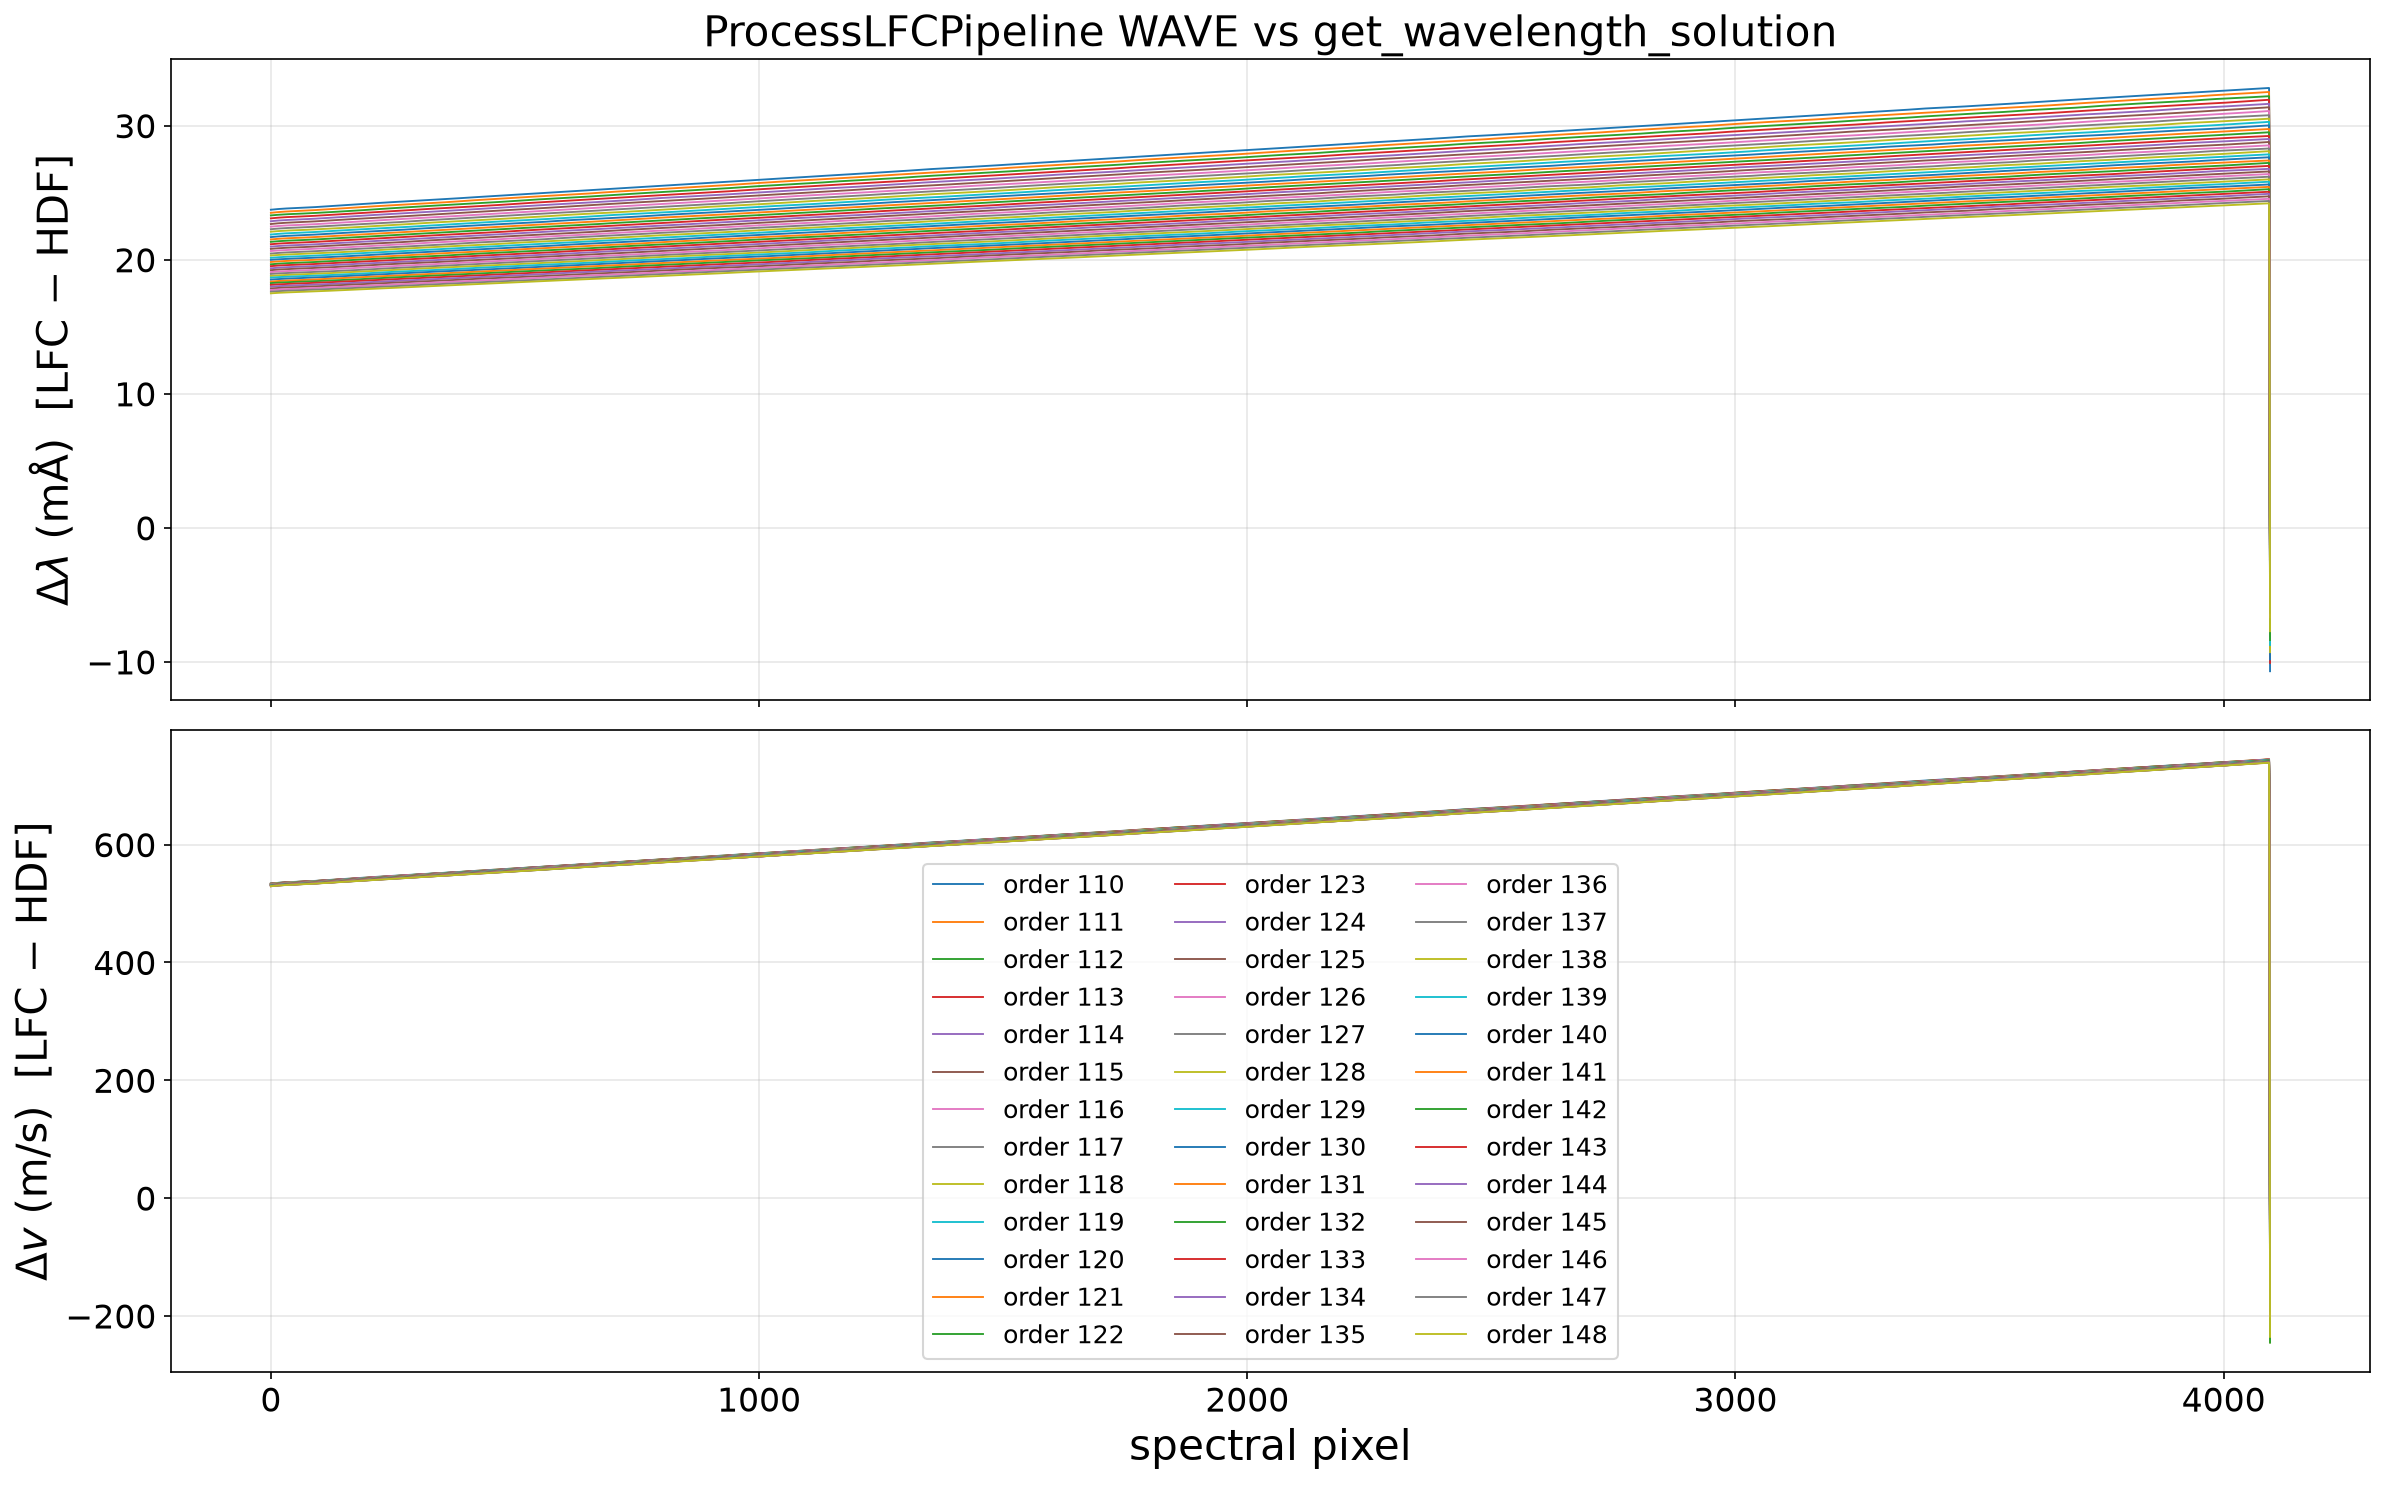

median Δv = 635.354 m/s  MAD = 52.440 m/s
  ord     med_mÅ    med_m/s    MAD_m/s
  110     28.277    638.776     52.797
  111     28.023    638.791     52.787
  112     27.764    638.593     52.751
  113     27.506    638.285     52.699
  114     27.247    637.881     52.661
  115     27.008    637.813     52.712
  116     26.762    637.503     52.616
  117     26.516    637.091     52.457
  118     26.311    637.542     52.856
  119     26.060    636.815     52.581
  120     25.831    636.516     52.770
  121     25.620    636.568     52.536
  122     25.407    636.487     52.584
  123     25.191    636.248     52.529
  124     24.993    636.390     52.543
  125     24.775    635.927     52.466
  126     24.579    635.940     52.353
  127     24.380    635.791     52.485
  128     24.178    635.476     52.301
  129     23.976    635.094     52.470
  130     23.790    635.037     52.240
  131     23.608    635.023     52.445
  132     23.420    634.778     52.180
  133     23.234    63

In [5]:
from hispecdrp.simulations.plotting import plot_lfc_vs_hdf_wavesol_shift
from hispecdrp.simulations.simulate_up_the_ramp import (
    wavelength_arrays_from_simulate_rate_map,
)


def _mad_frac(a: np.ndarray, b: np.ndarray) -> float:
    d = (a - b) / b
    d = d[np.isfinite(d)]
    if d.size == 0:
        return np.inf
    med = np.median(d)
    return float(np.median(np.abs(d - med)))


hdf_wave = wavelength_arrays_from_simulate_rate_map(
    SPECTROGRAPH, fibers=[FIBER]
)[FIBER]
if lfc_wave.shape != hdf_wave.shape:
    raise ValueError(
        f"WAVE shapes differ: KOA {lfc_wave.shape} vs HDF {hdf_wave.shape}"
    )
# Keck sim_wavesol increases along the detector; HDF get_wavelength decreases.
if _mad_frac(lfc_wave[:, ::-1], hdf_wave) < _mad_frac(lfc_wave, hdf_wave):
    lfc_wave = lfc_wave[:, ::-1]
    print("flipped KOA WAVE along the spectral axis to match HDF pixel convention")
stats = plot_lfc_vs_hdf_wavesol_shift(
    lfc_wave,
    hdf_wave,
    orders=order_list,
    out_path=OUT / "lfc_vs_hdf_wavesol.png",
)
print(
    f"median Δv = {stats['median_dvel_m_s']:.3f} m/s  "
    f"MAD = {stats['mad_dvel_m_s']:.3f} m/s"
)
print(f"{'ord':>5} {'med_mÅ':>10} {'med_m/s':>10} {'MAD_m/s':>10}")
for row in stats["per_order"]:
    print(
        f"{row['order']:5d} {row['median_dlam_um']*1e7:10.3f} "
        f"{row['median_dvel_m_s']:10.3f} {row['mad_dvel_m_s']:10.3f}"
    )


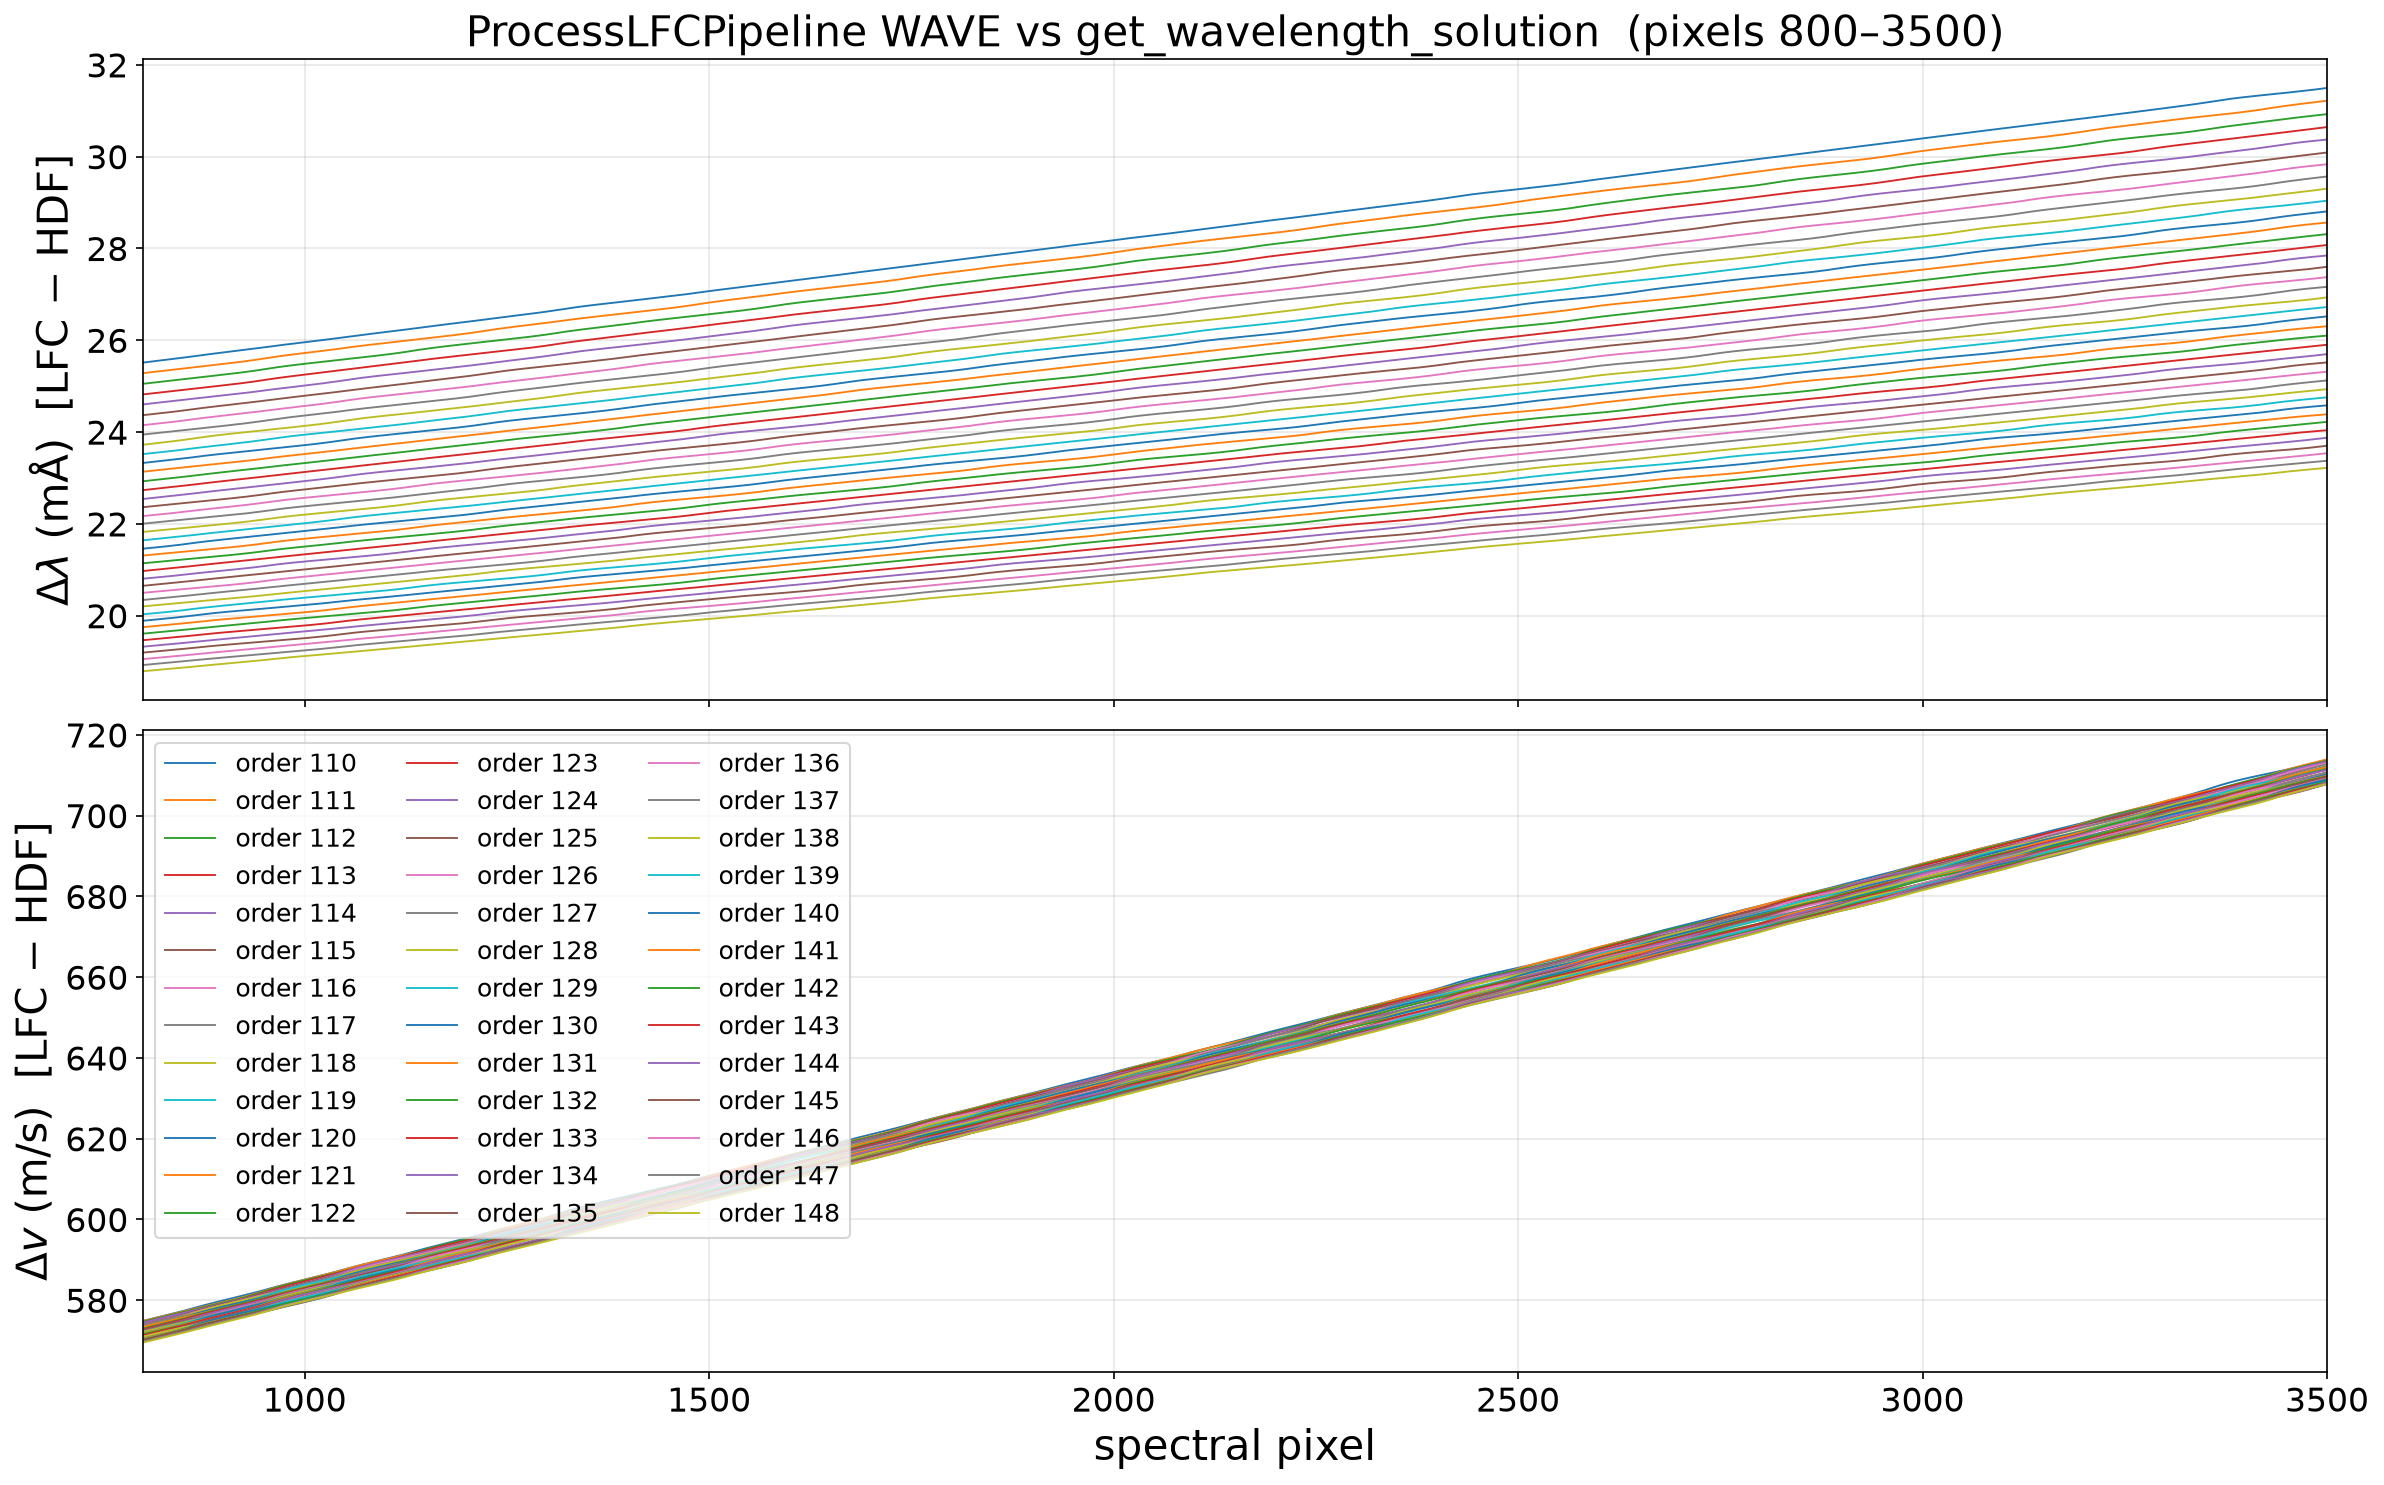

{'dlam_um': array([[ 2.37248028e-06,  2.37288099e-06,  2.37327333e-06, ...,
          3.28079225e-06,  2.21099541e-06, -1.07028578e-06],
        [ 2.34929278e-06,  2.34972213e-06,  2.35014226e-06, ...,
          3.25119530e-06,  2.46414496e-06, -7.87536661e-07],
        [ 2.33008383e-06,  2.33044611e-06,  2.33080106e-06, ...,
          3.21966960e-06,  2.44294740e-06, -7.76610222e-07],
        ...,
        [ 1.77327640e-06,  1.77357041e-06,  1.77385832e-06, ...,
          2.45412259e-06,  1.78560555e-06, -6.68726345e-07],
        [ 1.76129202e-06,  1.76158393e-06,  1.76186979e-06, ...,
          2.43783637e-06,  1.80336677e-06, -6.34473686e-07],
        [ 1.74873373e-06,  1.74902399e-06,  1.74930822e-06, ...,
          2.42022574e-06,  1.64877146e-06, -7.71817129e-07]],
       shape=(39, 4096)),
 'dvel_m_s': array([[ 533.80292279,  533.89403128,  533.98325804, ...,  744.63968938,
          501.82930392, -242.92260576],
        [ 533.38747626,  533.4859064 ,  533.58224306, ...,  744.623

In [6]:
plot_lfc_vs_hdf_wavesol_shift(
    lfc_wave,
    hdf_wave,
    orders=order_list,
    xlim=(800, 3500),
    out_path=OUT / "lfc_vs_hdf_wavesol_center.png",
)


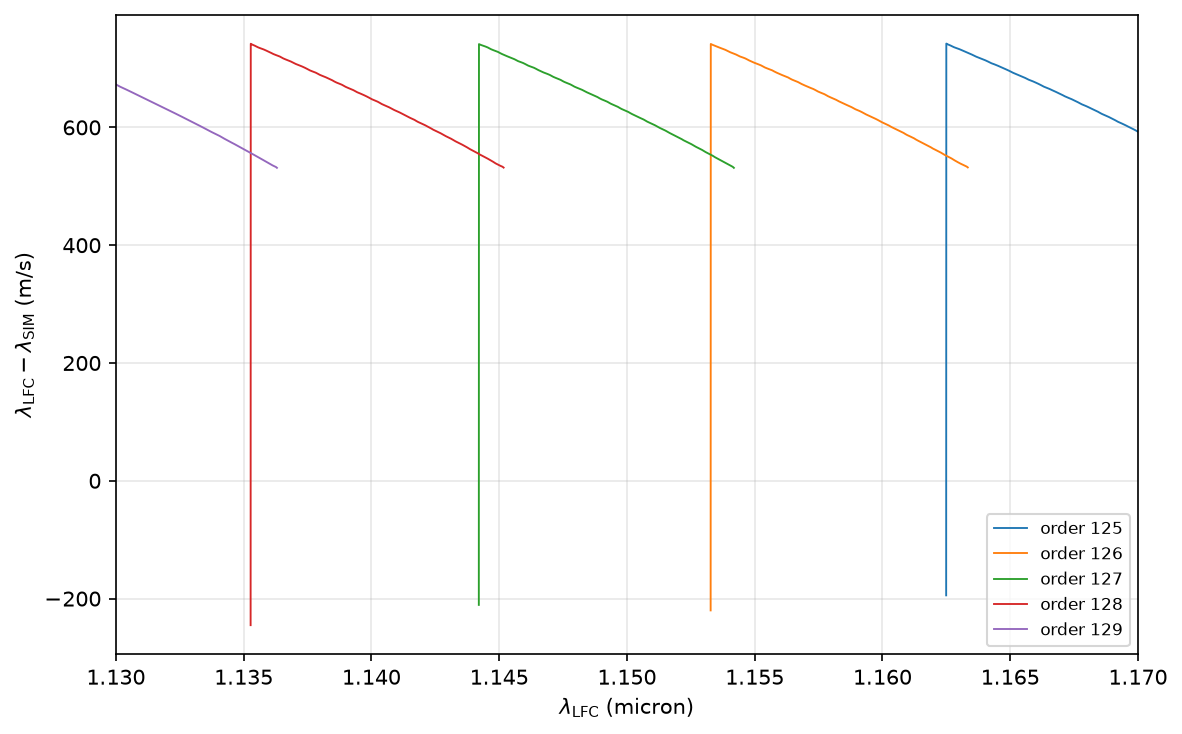

{'dlam_um': array([[ 2.37248028e-06,  2.37288099e-06,  2.37327333e-06, ...,
          3.28079225e-06,  2.21099541e-06, -1.07028578e-06],
        [ 2.34929278e-06,  2.34972213e-06,  2.35014226e-06, ...,
          3.25119530e-06,  2.46414496e-06, -7.87536661e-07],
        [ 2.33008383e-06,  2.33044611e-06,  2.33080106e-06, ...,
          3.21966960e-06,  2.44294740e-06, -7.76610222e-07],
        ...,
        [ 1.77327640e-06,  1.77357041e-06,  1.77385832e-06, ...,
          2.45412259e-06,  1.78560555e-06, -6.68726345e-07],
        [ 1.76129202e-06,  1.76158393e-06,  1.76186979e-06, ...,
          2.43783637e-06,  1.80336677e-06, -6.34473686e-07],
        [ 1.74873373e-06,  1.74902399e-06,  1.74930822e-06, ...,
          2.42022574e-06,  1.64877146e-06, -7.71817129e-07]],
       shape=(39, 4096)),
 'dvel_m_s': array([[ 533.80292279,  533.89403128,  533.98325804, ...,  744.63968938,
          501.82930392, -242.92260576],
        [ 533.38747626,  533.4859064 ,  533.58224306, ...,  744.623

In [7]:
from hispecdrp.simulations.plotting import plot_lfc_vs_hdf_wavesol_vs_wavelength

plot_lfc_vs_hdf_wavesol_vs_wavelength(
    lfc_wave,
    hdf_wave,
    orders=order_list,
    lam_xlim=(1.13, 1.17),
    out_path=OUT / "lfc_vs_hdf_wavesol_vs_lambda.png",
)
